In [1]:
import json
import matplotlib.pyplot as plt
import subprocess
import os

In [2]:
runner_dir = "runner"
prob_dir = "examples/sumfree_oxide_small"

# os.chdir(runner_dir)
subprocess.run(["cargo", "run", prob_dir + "/config.json", prob_dir, prob_dir + "/out.json"])

Cannot find provided config file


    Finished `dev` profile [unoptimized + debuginfo] target(s) in 0.23s
     Running `/cs/home/etl1/Documents/benchmarking/runner/target/debug/runner examples/sumfree_oxide_small/config.json examples/sumfree_oxide_small examples/sumfree_oxide_small/out.json`


CompletedProcess(args=['cargo', 'run', 'examples/sumfree_oxide_small/config.json', 'examples/sumfree_oxide_small', 'examples/sumfree_oxide_small/out.json'], returncode=0)

In [3]:
with open("/cs/home/etl1/Documents/benchmarking/runner/examples/sumfree_oxide_small/out.json") as f:
    data = json.load(f)

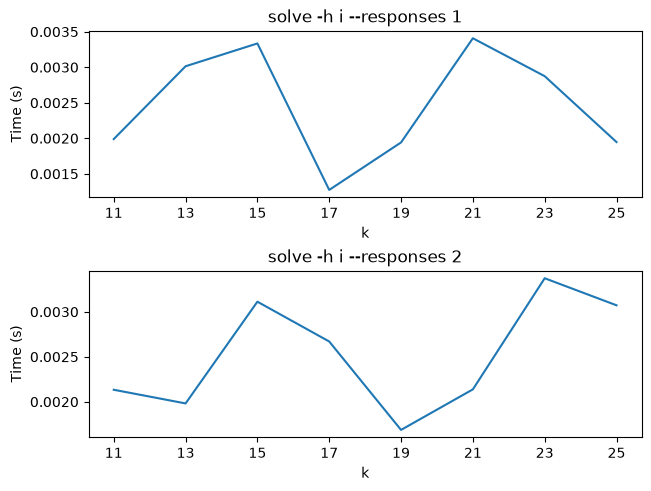

In [4]:
for option in data:
    fig, axs = plt.subplots(len(option["results"]), constrained_layout=True)
    for i, result in enumerate(option["results"]):
        x = []
        y = []
        for param_run in result["param_runs"]:
            x.append(param_run["name"][:-6].split("-")[1])
            y.append(param_run["total_time"])
            # print(f"{option["config"]["conjure_path"]}, response: {result["args"][-1]}, {param_run["name"]}, Total time: {param_run["total_time"]}")
        
        x, y = zip(*sorted(zip(x, y)))

        axs[i].plot(x,y)
        axs[i].set_title(" ".join(result["args"]))
        axs[i].set(xlabel="k", ylabel="Time (s)")
